# Practical 4: Polynomial Regression and the Bias-Variance Trade-off

**Subject:** Machine Learning  |  **Type:** Supervised learning, regression

## Aim
Demonstrate the use of **polynomial regression with varying polynomial degrees** on a suitable open-access dataset and observe the effect of **model complexity on prediction accuracy** in terms of the **bias-variance trade-off**.

## Dataset
**Auto MPG** (open access, `seaborn.load_dataset('mpg')`): relationship between a car's **horsepower** (input) and **mpg** (fuel efficiency, target). The relationship is clearly **curved**, so a straight line underfits. *If there is no internet, a synthetic curved dataset is used instead so every cell still runs.*

## Steps
1. Load data, plot it, see that it is curved
2. Split into train/test
3. Fit polynomial models of degree 1, 2, 3, 5, 8, 12
4. Plot the fitted curves (underfit, good fit, overfit)
5. Plot train error vs test error against degree (the U-shaped curve)
6. Choose the best degree with cross-validation
7. Estimate bias² and variance by resampling
8. Regularisation can tame high degrees (bonus)

## Step 0: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
np.random.seed(42)

## Step 1: Load data and look at it

Loaded Auto MPG dataset: (392, 9)


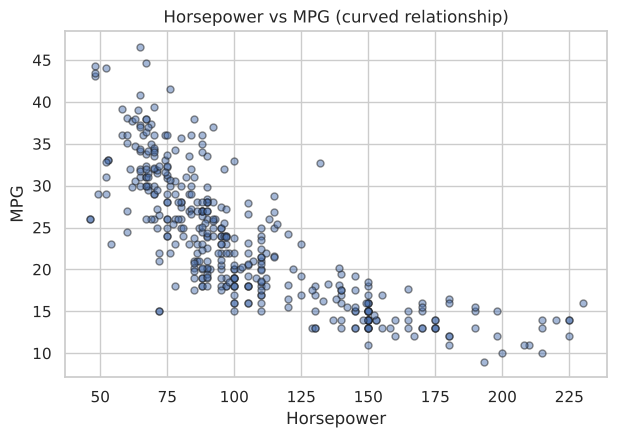

In [2]:
try:
    mpg = sns.load_dataset("mpg").dropna(subset=["horsepower", "mpg"])
    X_all = mpg[["horsepower"]].values.astype(float)
    y_all = mpg["mpg"].values.astype(float)
    xlabel, ylabel = "Horsepower", "MPG"
    print("Loaded Auto MPG dataset:", mpg.shape)
except Exception as e:
    print("Download failed, using synthetic curved data:", type(e).__name__)
    rng = np.random.default_rng(0)
    X_all = rng.uniform(40, 230, (392, 1))
    y_all = 50 - 0.35 * X_all[:, 0] + 0.0007 * X_all[:, 0] ** 2 + rng.normal(0, 3.5, 392)
    xlabel, ylabel = "Horsepower", "MPG"

plt.figure(figsize=(7, 4.5))
plt.scatter(X_all, y_all, alpha=0.5, edgecolor="k", s=25)
plt.xlabel(xlabel); plt.ylabel(ylabel); plt.title("Horsepower vs MPG (curved relationship)")
plt.show()

**How to read this:** each dot is a car. MPG falls as horsepower rises, but not along a straight line: it drops quickly at low horsepower and then flattens. A straight line cannot capture this bend, so we expect degree 1 to underfit.

## Step 2: Train/test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.3, random_state=1)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (274, 1) | Test: (118, 1)


## Step 3: Polynomial regression

A degree-$d$ polynomial model is

$$\hat{y} = b_0 + b_1 x + b_2 x^2 + \dots + b_d x^d$$

It is still **linear in the coefficients**, so we create the extra features $x^2, x^3, \dots$ with `PolynomialFeatures` and fit an ordinary linear regression. We standardise before the polynomial step so high powers do not blow up numerically.

In [4]:
def poly_model(d, reg=None):
    steps = [StandardScaler(), PolynomialFeatures(d, include_bias=False), StandardScaler()]
    steps.append(LinearRegression() if reg is None else reg)
    return make_pipeline(*steps)

degrees = [1, 2, 3, 5, 8, 12]
rows = []
for d in degrees:
    m = poly_model(d).fit(X_train, y_train)
    rows.append({
        "Degree": d,
        "Train MSE": mean_squared_error(y_train, m.predict(X_train)),
        "Test MSE": mean_squared_error(y_test, m.predict(X_test)),
        "Train R2": r2_score(y_train, m.predict(X_train)),
        "Test R2": r2_score(y_test, m.predict(X_test)),
    })
res = pd.DataFrame(rows).round(3)
res

,Degree,Train MSE,Test MSE,Train R2,Test R2
0,1,23.073,26.195,0.604,0.606
1,2,18.819,19.802,0.677,0.702
2,3,18.794,19.756,0.678,0.703
3,5,18.164,19.477,0.688,0.707
4,8,17.668,19.627,0.697,0.705
5,12,17.611,19.645,0.698,0.705


## Step 4: Plot the fitted curves

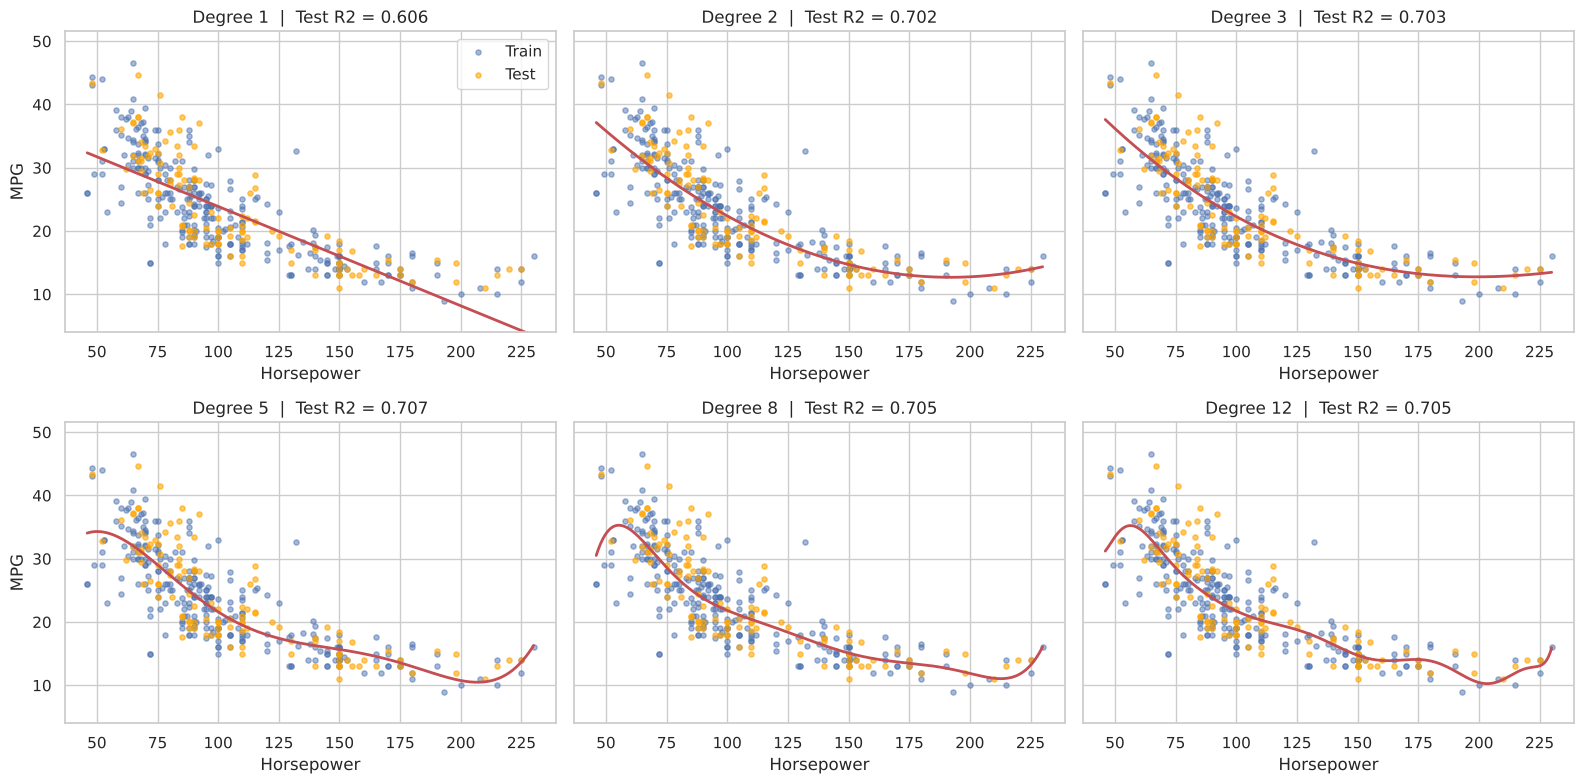

In [5]:
xs = np.linspace(X_all.min(), X_all.max(), 400).reshape(-1, 1)
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for ax, d in zip(axes.ravel(), degrees):
    m = poly_model(d).fit(X_train, y_train)
    ax.scatter(X_train, y_train, s=14, alpha=0.5, label="Train")
    ax.scatter(X_test, y_test, s=14, alpha=0.6, color="orange", label="Test")
    ax.plot(xs, m.predict(xs), "r", lw=2)
    ax.set_ylim(y_all.min() - 5, y_all.max() + 5)
    ax.set_title(f"Degree {d}  |  Test R2 = {r2_score(y_test, m.predict(X_test)):.3f}")
    ax.set_xlabel(xlabel)
axes[0, 0].legend(); axes[0, 0].set_ylabel(ylabel); axes[1, 0].set_ylabel(ylabel)
plt.tight_layout(); plt.show()

**How to read these six plots**
- **Degree 1 (straight line):** misses the bend. Errors are high on both train and test data, so it **underfits** (high bias, low variance).
- **Degree 2 to 3:** follows the curve smoothly. This is close to the best fit.
- **Degree 8 to 12:** the curve becomes wiggly and starts chasing individual points and noise, especially near the edges. Train error keeps shrinking but test error does not improve (or gets worse), so it **overfits** (low bias, high variance).

## Step 5: Train error vs test error against degree

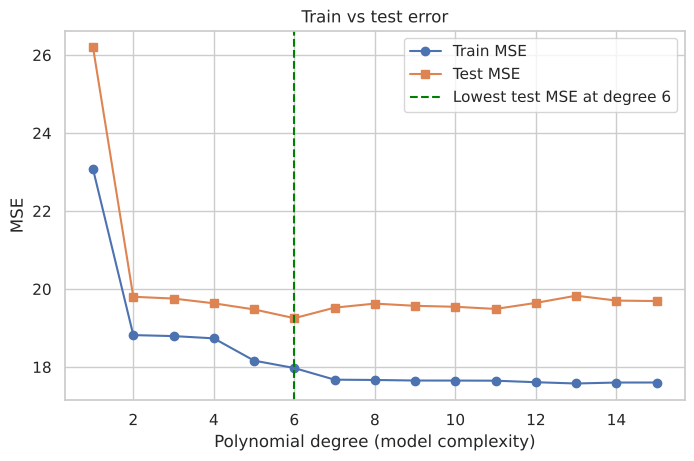

Degree with the lowest test MSE: 6


In [6]:
deg_range = list(range(1, 16))
tr_err, te_err = [], []
for d in deg_range:
    m = poly_model(d).fit(X_train, y_train)
    tr_err.append(mean_squared_error(y_train, m.predict(X_train)))
    te_err.append(mean_squared_error(y_test, m.predict(X_test)))

best_d = deg_range[int(np.argmin(te_err))]
plt.figure(figsize=(8, 4.8))
plt.plot(deg_range, tr_err, "o-", label="Train MSE")
plt.plot(deg_range, te_err, "s-", label="Test MSE")
plt.axvline(best_d, color="green", ls="--", label=f"Lowest test MSE at degree {best_d}")
plt.xlabel("Polynomial degree (model complexity)"); plt.ylabel("MSE")
plt.title("Train vs test error"); plt.legend(); plt.show()
print("Degree with the lowest test MSE:", best_d)

**How to read this graph (very important for the viva)**
- **X-axis:** model complexity (degree). **Y-axis:** error (MSE).
- **Train error (blue)** keeps falling as degree grows, because a more flexible model can fit the training points more closely.
- **Test error (orange)** falls sharply from degree 1 to degree 2 (about 26 to 20), then stays almost flat. The lowest point (green line) is the best trade-off, but degrees 2 to 12 are within about 0.5 MSE of each other.
- **Left (degree 1):** underfitting (high bias). **Right (high degrees):** the extra flexibility buys almost nothing on test data, and the gap between the blue and orange lines widens slowly: the start of overfitting.
- **Be honest in the viva:** on this dataset (274 training points, one input feature) the single test split shows only a *shallow* U. The overfitting is much clearer in the cross-validation curve (Step 6) and in the variance curve (Step 7), where the error rises sharply for degrees above about 8. With fewer samples or more noise, the test curve itself would rise steeply.

## Step 6: Choose the best degree with cross-validation

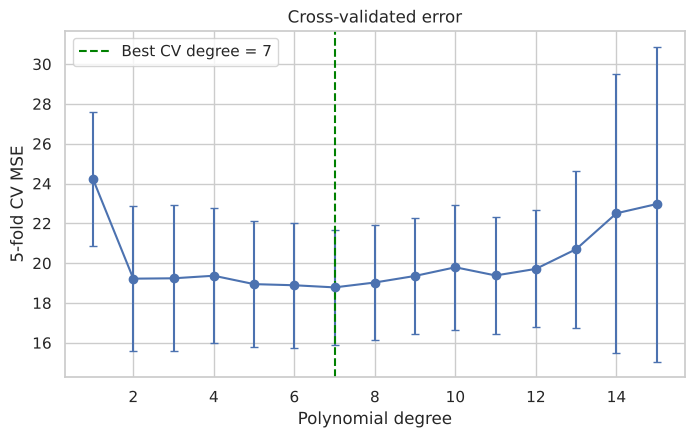

Best degree by 5-fold cross-validation: 7


In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mean, cv_std = [], []
for d in deg_range:
    s = -cross_val_score(poly_model(d), X_all, y_all, cv=kf, scoring="neg_mean_squared_error")
    cv_mean.append(s.mean()); cv_std.append(s.std())

best_cv = deg_range[int(np.argmin(cv_mean))]
plt.figure(figsize=(8, 4.5))
plt.errorbar(deg_range, cv_mean, yerr=cv_std, fmt="o-", capsize=3)
plt.axvline(best_cv, color="green", ls="--", label=f"Best CV degree = {best_cv}")
plt.xlabel("Polynomial degree"); plt.ylabel("5-fold CV MSE"); plt.legend(); plt.title("Cross-validated error")
plt.show()
print("Best degree by 5-fold cross-validation:", best_cv)

Cross-validation averages over 5 different splits, so it is a more reliable way to pick the degree than a single train/test split. Error bars show how much the score varies between folds.

**What the result means:** the CV error falls from degree 1 to 2 (about 24 to 19), stays flat until about degree 7 (its minimum, about 18.8), and then **rises clearly** (to about 23 at degree 15): this is the overfitting. Degrees 2 to 8 are almost equal, so by the "simplest adequate model" rule **degree 2** is a sensible choice (degree 7 is the strict minimum, but the gain over degree 2 is tiny and within the error bars).

## Step 7: Estimate bias² and variance by resampling

Total expected error = **Bias² + Variance + Irreducible noise**.

We approximate bias and variance with the **bootstrap**: refit each degree on 100 resampled training sets, then look at the predictions on the test points.
- **Variance:** how much the predictions change between resampled models.
- **Bias²:** how far the *average* prediction is from the truth (here measured against the observed test values, so it also contains the noise; treat it as an approximation).

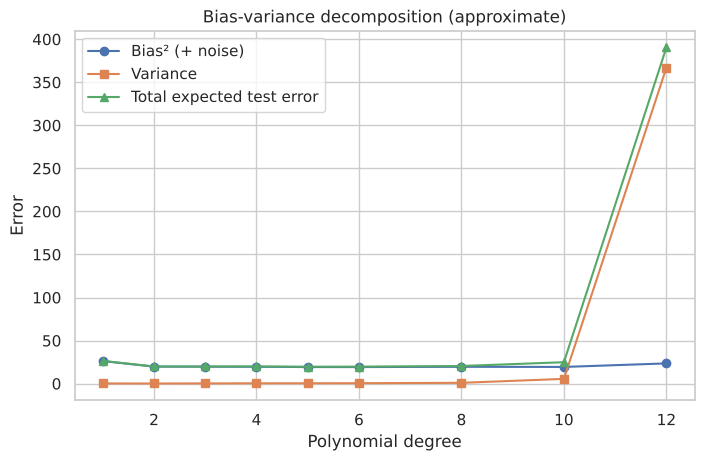

,Degree,Bias2,Variance,Total
0,1,26.20,0.18,26.39
1,2,19.74,0.14,19.89
2,3,19.67,0.23,19.90
3,4,19.56,0.37,19.93
4,5,19.24,0.39,19.63
5,6,19.23,0.50,19.73
6,8,19.54,0.92,20.46
7,10,19.37,5.50,24.87
8,12,23.48,366.91,390.40


In [8]:
rng = np.random.default_rng(0)
B = 100
bv_degrees = [1, 2, 3, 4, 5, 6, 8, 10, 12]
bias2, var, total = [], [], []
for d in bv_degrees:
    preds = np.zeros((B, len(X_test)))
    for b in range(B):
        idx = rng.integers(0, len(X_train), len(X_train))
        preds[b] = poly_model(d).fit(X_train[idx], y_train[idx]).predict(X_test)
    mean_pred = preds.mean(axis=0)
    bias2.append(np.mean((mean_pred - y_test) ** 2))
    var.append(np.mean(preds.var(axis=0)))
    total.append(np.mean((preds - y_test) ** 2))

plt.figure(figsize=(8, 4.8))
plt.plot(bv_degrees, bias2, "o-", label="Bias² (+ noise)")
plt.plot(bv_degrees, var, "s-", label="Variance")
plt.plot(bv_degrees, total, "^-", label="Total expected test error")
plt.xlabel("Polynomial degree"); plt.ylabel("Error"); plt.legend(); plt.title("Bias-variance decomposition (approximate)")
plt.show()
pd.DataFrame({"Degree": bv_degrees, "Bias2": np.round(bias2, 2), "Variance": np.round(var, 2), "Total": np.round(total, 2)})

**How to read this graph:** from degree 1 to about 6, **bias² falls** (the model becomes flexible enough to follow the curve: about 26 to 19) while **variance rises slowly** (0.2 to 0.5). The total error is lowest around degrees 2 to 6 where the two balance. Beyond degree 8, **variance explodes** (about 5 at degree 10 and several hundred at degree 12) because some resampled fits swing wildly, so total error shoots up. That is the **bias-variance trade-off** in one picture.

Notes: the bias² column also contains the irreducible noise (about 19 here), so it never goes near zero. At degree 12 the "bias²" value rises again only because a few extreme resampled fits distort the average prediction; do not over-interpret that point.

## Step 8 (bonus): Regularisation controls high-degree overfitting

Ridge regression adds a penalty on large coefficients, which flattens the wild curve of a high-degree polynomial.

**What to expect (read the titles of the plots):** the Ridge curve is smoother and tamer, but on this particular test split its MSE is *not* lower than plain degree 12 (about 20.7 vs 19.7), because alpha = 10 slightly over-smooths and OLS did not overfit badly on the dense part of this data. The value of Ridge here is stability (lower variance, less wild behaviour at the edges and for new samples), not a guaranteed lower test error. It pays off most when overfitting is severe (see Practical 5).

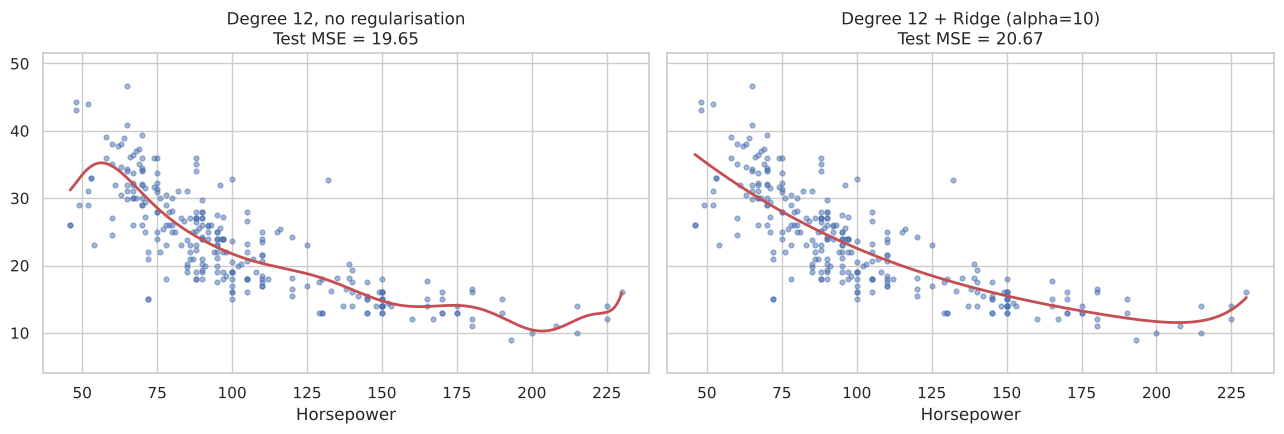

In [9]:
d = 12
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for a, (name, mdl) in zip(ax, [("Degree 12, no regularisation", poly_model(d)),
                              ("Degree 12 + Ridge (alpha=10)", poly_model(d, Ridge(alpha=10)))]):
    mdl.fit(X_train, y_train)
    a.scatter(X_train, y_train, s=12, alpha=0.5)
    a.plot(xs, mdl.predict(xs), "r", lw=2)
    a.set_ylim(y_all.min() - 5, y_all.max() + 5)
    a.set_title(f"{name}\nTest MSE = {mean_squared_error(y_test, mdl.predict(X_test)):.2f}")
    a.set_xlabel(xlabel)
plt.tight_layout(); plt.show()

## Result / Conclusion
- Degree 1 underfits (high bias): test MSE about 26. Degree 2 captures the curve (test MSE about 20); higher degrees add almost nothing on the test split (lowest at degree 6, cross-validation minimum at degree 7, differences tiny), so degree 2 is the simplest adequate model.
- Very high degrees show overfitting through rising cross-validation error and exploding variance (degrees above about 10), although the single test split shows it only mildly.
- Training error always decreases with complexity, so model selection must use test or cross-validation error, never training error.
- Regularisation (Ridge) smooths a high-degree model and reduces its variance, but it adds some bias: here it did not lower test MSE, because the plain model was not badly overfitted on this dataset.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is polynomial regression?**
Regression where the relationship between x and y is modelled as an n-th degree polynomial: $y = b_0 + b_1x + b_2x^2 + \dots + b_dx^d$. It captures curved relationships.

**Q2. Why is it called a linear model even though the curve is non-linear?**
Because it is linear in the parameters $b_0, b_1, \dots$. We transform x into $x, x^2, x^3$ and fit an ordinary linear regression on these new features.

**Q3. What does `PolynomialFeatures(degree=2)` do?**
For one input x it creates $[1, x, x^2]$. For two inputs (a, b) it creates $[1, a, b, a^2, ab, b^2]$, including interaction terms. `include_bias=False` drops the constant column because the regression already has an intercept.

**Q4. When do you use polynomial regression?**
When a scatter plot shows a curved relationship that a straight line cannot capture.

**Q5. What is bias?**
Error from wrong or overly simple assumptions in the model. High bias causes underfitting.

**Q6. What is variance?**
Error from sensitivity to small changes in the training data. High variance causes overfitting because the model learns noise.

**Q7. Explain the bias-variance trade-off.**
Increasing model complexity lowers bias but raises variance. Expected test error = Bias² + Variance + Irreducible noise. The goal is the sweet spot of minimum total error.

**Q8. What is underfitting?**
The model is too simple to capture the pattern. Both training and test errors are high.

**Q9. What is overfitting?**
The model fits training data (and its noise) too closely. Training error is very low but test error is high.

**Q10. How do you detect overfitting?**
A large gap between training performance and test performance. Learning curves and cross-validation also show it.

**Q11. How do you reduce overfitting?**
Lower the polynomial degree, get more data, use regularisation (Ridge/Lasso), use cross-validation for model selection, remove features, or use early stopping.

**Q12. How do you choose the best degree?**
Compare test or cross-validation error for several degrees and choose the lowest, preferring the simplest degree when scores are similar.

**Q13. What is irreducible error?**
Noise inherent in the data that no model can remove.

**Q14. What happens to the number of features as the degree grows?**
It grows very quickly with multiple inputs (combinatorially), which raises computation and the risk of overfitting.

**Q15. Why scale features before polynomial regression?**
$x^{12}$ creates huge values and numerical instability. Scaling keeps the numbers manageable.

**Q16. Can training R² alone judge the model?**
No. Training R² always rises with degree. Judge on test data or cross-validation.

**Q17. Can polynomial regression extrapolate well?**
No. Outside the training range, high-degree polynomials give extreme, unreliable predictions.

**Q18. What is Runge's phenomenon?**
High-degree polynomials oscillate wildly near the edges of the data range, which is why the high-degree curve swings at the ends.

**Q19. What is the difference between polynomial regression and linear regression?**
Linear regression fits a straight line (or hyperplane). Polynomial regression fits a curve by adding powers of the inputs as extra features. Linear regression is polynomial regression of degree 1.

**Q20. Is polynomial regression a parametric model?**
Yes; the number of parameters is fixed by the degree.

**Q21. Which metrics did you use?**
MSE and R² on both train and test sets, plus cross-validated MSE.

## B. Questions about the graphs

**G1. What does the scatter plot of horsepower vs MPG show?**
A negative, curved relationship: MPG decreases as horsepower increases, steeply at first and then flattening. This is why a straight line is not enough.

**G2. What does the degree 1 curve look like and what does it mean?**
A straight line that misses the curvature. Both train and test errors are high, so it underfits (high bias, low variance).

**G3. What does a very high degree curve look like?**
A wiggly curve that bends to follow individual points and can swing wildly at the edges. Train error is very low but test error is not better, so it overfits (low bias, high variance).

**G4. Explain the train/test error versus degree graph.**
Train error keeps falling as degree rises. Test error falls first, reaches a minimum (the best degree) and then flattens or rises. The gap between the two lines widens with overfitting.

**G5. Where is the best model on that graph?**
At the degree with the lowest test (or cross-validation) error, where bias and variance are balanced. In my run the test error is lowest at degree 6 and the CV error at degree 7, but degree 2 is almost as good, so I prefer the simpler model.

**G5b. Your test-error curve is almost flat after degree 2. Why is there no clear U-shape?**
The dataset has one input feature and about 270 training points, so even a high-degree polynomial is well constrained in the dense region and the test split changes little. The overfitting shows up where data is sparse (the edges), which is why cross-validation error rises and the bootstrap variance explodes at high degrees. With less data or more noise the U-shape on the test curve would be much sharper.

**G6. Why does the curve swing at the ends for high degrees?**
High-degree terms grow very fast outside the dense data region, so small coefficient changes cause large swings (Runge's phenomenon). Few data points at the edges also give the model little to constrain it.

**G7. What does the bias-variance graph show?**
Bias² decreases and variance increases as the degree rises; the total error is lowest where they balance.

**G8. What do the error bars in the cross-validation plot mean?**
The standard deviation of the error across the 5 folds. Large bars mean the score is unstable and the differences between nearby degrees may not be meaningful.

**G9. What does the Ridge plot show compared with the plain degree-12 plot?**
The Ridge curve is smoother and less wiggly because the penalty shrinks large coefficients, so variance decreases. In my run the test MSE was slightly higher than the unregularised model (about 20.7 vs 19.7) because the penalty added a little bias and the unregularised model was not badly overfitted on this data. Ridge helps most when overfitting is severe.

## C. Code questions

**C1. Why use a pipeline?**
It chains scaling, polynomial feature creation and regression so the same steps are applied consistently to train and test data and leakage is avoided.

**C2. What does `make_pipeline` do?**
Builds a Pipeline with automatically named steps.

**C3. Why `np.linspace` and `reshape(-1, 1)`?**
To create a smooth grid of x values (one column) for drawing the fitted curve, since scikit-learn expects a 2-D array.

**C4. Why do we reshape X to 2-D?**
scikit-learn features must be shaped (n_samples, n_features).

**C5. What does the bootstrap do in Step 7?**
It resamples the training data with replacement many times, fits a model on each resample, and uses the spread of the predictions to estimate variance.